# code_076 · Rules sparse scores and symbolic models

**Book:** section 15.5. A self-contained transparent response-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_15_GUIDE.md), [run evidence](../CHAPTER_15_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_076).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1576;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1576


<a id="units"></a>
## Restrict the expression search and preserve dimensions

Generate a simply supported ideal beam with central point load: P in10–50kN, L in2–5m, EI in1–8MN m². True deflection=P*L³/(48*EI) metres, plus independent .1mm response noise. These assumptions are synthetic, not field mechanics validation. Training250, development120, final300. Search only three predeclared dimensionally valid dictionaries: beam term P*L³/EI; that term plus its dimensionless load interaction; or that term plus its dimensionless span interaction. Fit coefficients on training, choose development MSE +1e-9 m² per term. This finite dictionary is a scoped symbolic search, not an exhaustive symbolic-regression implementation. Reject P/EI with a declared dimensionless coefficient because it has units m^-2 rather than m. A coefficient with different units could define a different, valid model; units do not prohibit all sums or all alternative formulas.


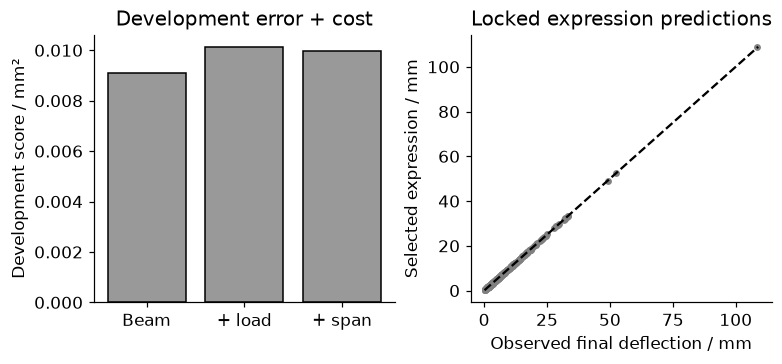

In [2]:
from sklearn.linear_model import LinearRegression,LogisticRegression
from sklearn.metrics import mean_squared_error,accuracy_score,brier_score_loss
from sklearn.tree import DecisionTreeClassifier
def generate(n):
 a=np.column_stack([rng.uniform(1e4,5e4,n),rng.uniform(2,5,n),rng.uniform(1e6,8e6,n)]);truth=a[:,0]*a[:,1]**3/(48*a[:,2]);return a,truth+rng.normal(0,1e-4,n)
X,y=generate(250);Xd,yd=generate(120);Xt,yt=generate(300)
def terms(a):
 beam=a[:,0]*a[:,1]**3/a[:,2];return np.column_stack([beam,beam*(a[:,0]/3e4),beam*(a[:,1]/3)])
# Dimensions represented by exponents of force and length.
P=np.array([1,0]);L=np.array([0,1]);EI=np.array([1,2]);np.testing.assert_array_equal(P+3*L-EI,[0,1]);assert not np.array_equal(P-EI,[0,1]);assert np.array_equal(P-P,L-L)
dictionaries={'beam':[0],'beam + load interaction':[0,1],'beam + span interaction':[0,2]};models={};selection={};rows=[]
for name,cols in dictionaries.items():
 model=LinearRegression(fit_intercept=False).fit(terms(X)[:,cols],y);models[name]=model;dev_mse=float(mean_squared_error(yd,model.predict(terms(Xd)[:,cols])));selection[name]=dev_mse+1e-9*len(cols);rows.append({'expression':name,'terms':len(cols),'development_mse_m2':dev_mse,'selection_score_m2':selection[name],'coefficient_dimensionless':model.coef_.tolist()})
selected=min(selection,key=selection.get);cols=dictionaries[selected];pred=models[selected].predict(terms(Xt)[:,cols]);RESULTS['symbolic']={'candidates':rows,'selected':selected,'selected_final_mse_m2':float(mean_squared_error(yt,pred)),'true_beam_coefficient':1/48,'dimension_guard_rejected_P_over_EI_with_unitless_coefficient':True,'search_scope':'three fixed dictionaries only','roles':{'train':250,'development':120,'final':300}}
# Converting P from kN and EI from MN m² recovers the same SI expression.
np.testing.assert_allclose((X[:,0]/1e3)*1e3*X[:,1]**3/((X[:,2]/1e6)*1e6),terms(X)[:,0])
fig,axes=plt.subplots(1,2,figsize=(7,3.2));axes[0].bar(range(3),[r['selection_score_m2']*1e6 for r in rows],color='.6',edgecolor='black');axes[0].set(xticks=range(3),xticklabels=['Beam','+ load','+ span'],ylabel='Development score / mm²',title='Development error + cost');axes[1].scatter(yt*1e3,pred*1e3,s=12,color='.5');limits=[min(yt.min(),pred.min())*1e3,max(yt.max(),pred.max())*1e3];axes[1].plot(limits,limits,'--',color='black');axes[1].set(xlabel='Observed final deflection / mm',ylabel='Selected expression / mm',title='Locked expression predictions');plt.show()


<a id="rules"></a>
## Compact rules can lose important interactions

A separate binary decision flags observed deflection>3mm. Fixed decision list: if EI>5MN m², return negative; otherwise if span>4m, positive; otherwise load>35kN. Fixed sparse score: 1*(load>30kN)+2*(span>3.5m)-2*(EI>4MN m²), positive when score>=1. A fixed four-leaf tree learns thresholds from training. A small rule ensemble fits logistic weights to four predeclared binary rules, including a span/stiffness interaction. Fixed C1, threshold.5. Report final target accuracy and agreement with the selected beam expression threshold; these are different fidelity targets. No rule is claimed causal, universally safe or equivalent to RuleFit. No final-driven rule edits.


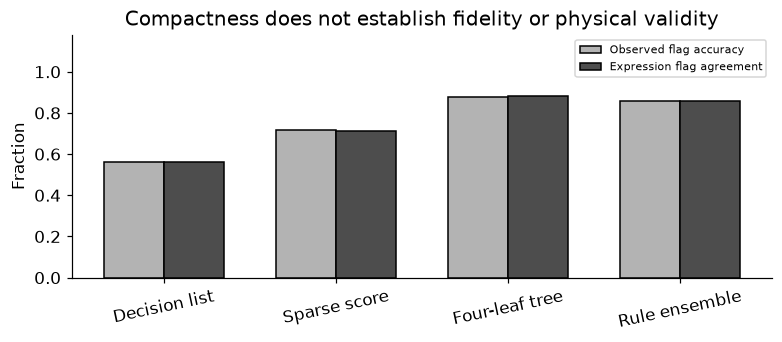

In [3]:
def rule_features(a):return np.column_stack([a[:,0]>3e4,a[:,1]>3.5,a[:,2]<4e6,(a[:,1]>4)&(a[:,2]<3e6)]).astype(float)
def decision_list(a):return np.where(a[:,2]>5e6,False,np.where(a[:,1]>4,True,a[:,0]>3.5e4))
def score(a):return (a[:,0]>3e4)+2*(a[:,1]>3.5)-2*(a[:,2]>4e6)
train_label=y>.003;final_label=yt>.003;reference=pred>.003;tree=DecisionTreeClassifier(max_leaf_nodes=4,max_depth=3,random_state=SEED).fit(X,train_label);ensemble=LogisticRegression(C=1,max_iter=1000).fit(rule_features(X),train_label);rule_pred={'Decision list':decision_list(Xt),'Sparse score':score(Xt)>=1,'Four-leaf tree':tree.predict(Xt),'Rule ensemble':ensemble.predict_proba(rule_features(Xt))[:,1]>=.5};rule_rows=[]
for name,p in rule_pred.items():rule_rows.append({'method':name,'final_target_accuracy':float(accuracy_score(final_label,p)),'agreement_with_selected_expression_flag':float(np.mean(p==reference)),'final_rows':300,'positive_targets':int(final_label.sum())})
assert set(np.unique(score(Xt)))<=set(range(-2,4));assert all(len(p)==300 for p in rule_pred.values());RESULTS['rules']=rule_rows;RESULTS['rule_ensemble']={'features':['load>30kN','span>3.5m','EI<4MN_m2','span>4m AND EI<3MN_m2'],'weights':ensemble.coef_[0].tolist(),'intercept':float(ensemble.intercept_[0]),'threshold':.5};RESULTS['tree_leaves']=int(tree.get_n_leaves())
fig,ax=plt.subplots(figsize=(7,3));positions=np.arange(4)
for j,key in enumerate(['final_target_accuracy','agreement_with_selected_expression_flag']):ax.bar(positions+(j-.5)*.35,[r[key] for r in rule_rows],width=.35,color=['.7','.3'][j],edgecolor='black',label=['Observed flag accuracy','Expression flag agreement'][j])
ax.set(xticks=positions,xticklabels=list(rule_pred),ylim=(0,1.18),ylabel='Fraction',title='Compactness does not establish fidelity or physical validity');ax.tick_params(axis='x',labelrotation=12);ax.legend(fontsize=7);plt.show()


In [4]:
summary={'example_id':'code_076','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['finite symbolic dictionary with dimensional guards', 'development complexity selection and locked assessment', 'decision list sparse score and rule ensemble', 'compactness fidelity and expression limits'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["finite symbolic dictionary with dimensional guards", "development complexity selection and locked assessment", "decision list sparse score and rule ensemble", "compactness fidelity and expression limits"], "elapsed_seconds": 0.283, "example_id": "code_076", "hardware": "Darwin arm64 CPU", "results": {"rule_ensemble": {"features": ["load>30kN", "span>3.5m", "EI<4MN_m2", "span>4m AND EI<3MN_m2"], "intercept": -2.03739955825395, "threshold": 0.5, "weights": [1.374671986719648, 3.9493918394557146, 2.077797805704131, 0.2281030798180117]}, "rules": [{"agreement_with_selected_expression_flag": 0.56, "final_rows": 300, "final_target_accuracy": 0.5633333333333334, "method": "Decision list", "positive_targets": 217}, {"agreement_with_selected_expression_flag": 0.7133333333333334, "final_rows": 300, "final_target_accuracy": 0.7166666666666667, "method": "Sparse score", "positive_targets": 217}, {"agreement_with_selected_expression_flag": 0.88, "f